# DS_Day01_09 — Hospital: Does Weather Affect Patient Arrivals?
**Industry:** Healthcare & Public Health | **Algorithm:** Linear Regression

**Workflow:** Load → Clean → EDA → 4 Visualisations → Statistical tests → Linear Regression → Insights & Action Plan

> **Run cells top to bottom** (Runtime → Run all).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 50)

## 1. Load the data
Set `USE_SAMPLE_DATA = False` and upload your own file(s) when you have the real dataset.

Two accepted layouts:
- **One merged CSV** with: `Date, Department, Outpatient_Count, Emergency_Count, Temperature, Rainfall, Humidity, Air_Quality`
- **Two CSVs**: a hospital file (`Date, Department, Outpatient_Count, Emergency_Count`) and a weather file (`Date, Temperature, Rainfall, Humidity, Air_Quality`)

In [2]:
USE_SAMPLE_DATA = True   # <-- change to False to upload your real data

def make_sample_data(seed=42):
    """Synthetic 2-year dataset with realistic weather effects (for practice only)."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2023-01-01", "2024-12-31", freq="D")
    doy = dates.dayofyear.values
    n = len(dates)

    # --- Weather (Tamil Nadu-like: hot summer, monsoon Oct-Dec) ---
    temp = 29 + 5*np.sin(2*np.pi*(doy-90)/365) + rng.normal(0, 1.8, n)
    monsoon = np.asarray((dates.month >= 10) | (dates.month == 6))
    rain = np.where(rng.random(n) < np.where(monsoon, 0.45, 0.12),
                    rng.exponential(np.where(monsoon, 14, 6), n), 0.0)
    humidity = np.clip(60 + 0.9*rain + 8*np.cos(2*np.pi*(doy-30)/365) + rng.normal(0, 6, n), 25, 100)
    aqi = np.clip(90 + 0.15*(temp-29)*10 - 0.8*rain + 25*np.cos(2*np.pi*(doy-10)/365)
                  + rng.normal(0, 18, n), 20, 400)
    weather = pd.DataFrame({"Date": dates, "Temperature": temp.round(1), "Rainfall": rain.round(1),
                            "Humidity": humidity.round(0), "Air_Quality": aqi.round(0)})

    # --- Hospital (weather sensitivity differs by department) ---
    depts = {  # base_out, base_er, temp_sens, rain_sens, aqi_sens, humid_sens
        "General Medicine": (120, 25, 0.004, 0.002, 0.002, 0.001),
        "Pediatrics":       (70,  15, 0.000, 0.006, 0.003, 0.004),
        "Respiratory":      (55,  12, 0.000, 0.003, 0.012, 0.004),
        "Cardiology":       (45,  14, 0.012, 0.000, 0.004, 0.000),
        "Orthopedics":      (50,  10, 0.000, 0.010, 0.000, 0.000),
        "Dermatology":      (40,   3, 0.008, 0.000, 0.001, 0.005),
    }
    dow_factor = np.array([1.15, 1.10, 1.05, 1.0, 1.0, 0.85, 0.6])[dates.dayofweek]
    rows = []
    for d, (bo, be, ts, rs, as_, hs) in depts.items():
        lift = (ts*np.abs(temp-29)*3 + rs*rain + as_*(aqi-90) + hs*(humidity-60))
        out = rng.poisson(np.clip(bo*dow_factor*(1+lift), 1, None))
        er  = rng.poisson(np.clip(be*(1+1.6*lift+0.03*(dow_factor > 1)), 1, None))
        rows.append(pd.DataFrame({"Date": dates, "Department": d,
                                  "Outpatient_Count": out, "Emergency_Count": er}))
    hospital = pd.concat(rows, ignore_index=True)

    # --- Inject realistic "dirty data" so the cleaning step has work to do ---
    idx = rng.choice(hospital.index, 40, replace=False)
    hospital.loc[idx[:20], "Outpatient_Count"] = np.nan
    hospital.loc[idx[20:], "Emergency_Count"] = np.nan
    hospital.loc[rng.choice(hospital.index, 5), "Outpatient_Count"] = -10        # impossible values
    hospital.loc[rng.choice(hospital.index, 3), "Emergency_Count"] = 900         # outliers
    hospital = pd.concat([hospital, hospital.sample(25, random_state=1)], ignore_index=True)  # duplicates
    weather.loc[rng.choice(weather.index, 12), "Temperature"] = np.nan
    weather.loc[rng.choice(weather.index, 8), "Air_Quality"] = np.nan
    return hospital, weather

if USE_SAMPLE_DATA:
    hospital_raw, weather_raw = make_sample_data()
    print("Using SAMPLE data.")
else:
    from google.colab import files
    print("Upload your CSV file(s) (select both files if you have two):")
    up = files.upload()
    frames = {k: pd.read_csv(k) for k in up}
    if len(frames) == 1:
        merged = list(frames.values())[0]
        hospital_raw = merged[["Date","Department","Outpatient_Count","Emergency_Count"]]
        weather_raw = (merged[["Date","Temperature","Rainfall","Humidity","Air_Quality"]]
                       .drop_duplicates("Date"))
    else:
        for name, f in frames.items():
            if "Department" in f.columns: hospital_raw = f
            else: weather_raw = f

print("Hospital:", hospital_raw.shape, "| Weather:", weather_raw.shape)
hospital_raw.head()

Using SAMPLE data.
Hospital: (4411, 4) | Weather: (731, 5)


,Date,Department,Outpatient_Count,Emergency_Count
0,2023-01-01,General Medicine,72.0,29.0
1,2023-01-02,General Medicine,164.0,32.0
2,2023-01-03,General Medicine,158.0,22.0
3,2023-01-04,General Medicine,129.0,22.0
4,2023-01-05,General Medicine,119.0,23.0


## 2. Clean & validate

In [3]:
hospital, weather = hospital_raw.copy(), weather_raw.copy()
hospital["Date"] = pd.to_datetime(hospital["Date"], errors="coerce")
weather["Date"]  = pd.to_datetime(weather["Date"],  errors="coerce")

print("--- BEFORE CLEANING ---")
print("Hospital missing:\n", hospital.isna().sum(), "\nDuplicates:", hospital.duplicated().sum())
print("Weather missing:\n", weather.isna().sum(), "\nDuplicates:", weather.duplicated("Date").sum())

# 1) Drop bad dates and exact duplicates
hospital = hospital.dropna(subset=["Date"]).drop_duplicates()
weather  = weather.dropna(subset=["Date"]).drop_duplicates("Date")

# 2) Impossible values (negative counts) -> missing
for c in ["Outpatient_Count", "Emergency_Count"]:
    hospital.loc[hospital[c] < 0, c] = np.nan

# 3) Outliers: cap at Q3 + 3*IQR within each department (keeps genuine surges, removes typos)
def cap_outliers(g, col):
    q1, q3 = g[col].quantile([.25, .75]); upper = q3 + 3*(q3-q1)
    return g[col].where(g[col] <= upper, np.nan)
for c in ["Outpatient_Count", "Emergency_Count"]:
    hospital[c] = hospital.groupby("Department", group_keys=False).apply(lambda g: cap_outliers(g, c))

# 4) Fill missing: counts -> department median; weather -> time interpolation
for c in ["Outpatient_Count", "Emergency_Count"]:
    hospital[c] = hospital.groupby("Department")[c].transform(lambda s: s.fillna(s.median())).round().astype(int)
weather = weather.sort_values("Date").set_index("Date")
weather = weather.interpolate(method="time").ffill().bfill().reset_index()

print("\n--- AFTER CLEANING ---")
print("Hospital missing:", hospital.isna().sum().sum(), "| Weather missing:", weather.isna().sum().sum())
print("Hospital shape:", hospital.shape, "| Weather shape:", weather.shape)

--- BEFORE CLEANING ---
Hospital missing:
 Date                 0
Department           0
Outpatient_Count    20
Emergency_Count     20
dtype: int64 
Duplicates: 25
Weather missing:
 Date            0
Temperature    12
Rainfall        0
Humidity        0
Air_Quality     8
dtype: int64 
Duplicates: 0

--- AFTER CLEANING ---
Hospital missing: 0 | Weather missing: 0
Hospital shape: (4386, 4) | Weather shape: (731, 5)


/tmp/ipykernel_3386/3519097732.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hospital[c] = hospital.groupby("Department", group_keys=False).apply(lambda g: cap_outliers(g, c))
/tmp/ipykernel_3386/3519097732.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hospital[c] = hospital.groupby("Department", group_keys=False).apply(lambda g: cap_outliers(g, c))


## 3. Merge healthcare + weather data

In [4]:
df = hospital.merge(weather, on="Date", how="left", validate="many_to_one")
df["Total_Patients"] = df["Outpatient_Count"] + df["Emergency_Count"]
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")
df["Year"] = df["Date"].dt.year
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["Season"] = df["Month"].map({12:"Winter",1:"Winter",2:"Winter",3:"Summer",4:"Summer",5:"Summer",
                                6:"Monsoon",7:"Monsoon",8:"Monsoon",9:"Monsoon",10:"NE Monsoon",11:"NE Monsoon"})

# Weather condition label (priority order: rain > heat > poor air > cold > normal)
t_hi, t_lo = df["Temperature"].quantile(.90), df["Temperature"].quantile(.10)
aq_hi = df["Air_Quality"].quantile(.90)
def condition(r):
    if r.Rainfall >= 20:      return "Heavy Rain"
    if r.Temperature >= t_hi: return "Extreme Heat"
    if r.Air_Quality >= aq_hi:return "Poor Air Quality"
    if r.Temperature <= t_lo: return "Cool"
    return "Normal"
df["Weather_Condition"] = df.apply(condition, axis=1)
print(f"Extreme heat >= {t_hi:.1f}C | Cool <= {t_lo:.1f}C | Poor air AQI >= {aq_hi:.0f}")
print(df["Weather_Condition"].value_counts())
df.head()

Extreme heat >= 34.2C | Cool <= 23.8C | Poor air AQI >= 118
Weather_Condition
Normal              3090
Extreme Heat         450
Poor Air Quality     432
Cool                 294
Heavy Rain           120
Name: count, dtype: int64


,Date,Department,Outpatient_Count,Emergency_Count,Temperature,Rainfall,Humidity,Air_Quality,Total_Patients,Month,Month_Name,Year,DayOfWeek,Season,Weather_Condition
0,2023-01-01,General Medicine,72,29,24.6,0.0,64.0,124.0,101,1,Jan,2023,6,Winter,Poor Air Quality
1,2023-01-02,General Medicine,164,32,22.1,21.0,85.0,109.0,196,1,Jan,2023,0,Winter,Heavy Rain
2,2023-01-03,General Medicine,158,22,25.4,0.0,68.0,128.0,180,1,Jan,2023,1,Winter,Poor Air Quality
3,2023-01-04,General Medicine,129,22,25.7,0.0,71.0,96.0,151,1,Jan,2023,2,Winter,Normal
4,2023-01-05,General Medicine,119,23,20.5,10.7,83.0,44.0,142,1,Jan,2023,3,Winter,Cool


## 4. Exploratory data analysis

In [5]:
print(df.info())
display(df[["Outpatient_Count","Emergency_Count","Total_Patients","Temperature","Rainfall","Humidity","Air_Quality"]].describe().round(2))
display(df.groupby("Department")[["Outpatient_Count","Emergency_Count","Total_Patients"]].agg(["mean","std","max"]).round(1))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4386 entries, 0 to 4385
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               4386 non-null   datetime64[ns]
 1   Department         4386 non-null   object        
 2   Outpatient_Count   4386 non-null   int64         
 3   Emergency_Count    4386 non-null   int64         
 4   Temperature        4386 non-null   float64       
 5   Rainfall           4386 non-null   float64       
 6   Humidity           4386 non-null   float64       
 7   Air_Quality        4386 non-null   float64       
 8   Total_Patients     4386 non-null   int64         
 9   Month              4386 non-null   int32         
 10  Month_Name         4386 non-null   object        
 11  Year               4386 non-null   int32         
 12  DayOfWeek          4386 non-null   int32         
 13  Season             4386 non-null   object        
 14  Weather_

,Outpatient_Count,Emergency_Count,Total_Patients,Temperature,Rainfall,Humidity,Air_Quality
count,4386.00,4386.00,4386.00,4386.00,4386.00,4386.00,4386.00
mean,63.83,14.41,78.24,28.92,2.39,62.23,88.98
std,31.23,8.59,37.79,3.94,7.50,10.08,21.98
min,9.00,0.00,10.00,19.90,0.00,38.00,20.00
25%,43.00,8.00,52.00,25.70,0.00,56.00,74.00
50%,55.00,14.00,68.00,28.80,0.00,62.00,89.00
75%,75.00,20.00,92.00,32.20,0.00,68.00,103.00
max,191.00,49.00,219.00,38.00,133.30,100.00,165.00


Outpatient_Count            Emergency_Count           \
                             mean   std  max            mean  std max   
Department                                                              
Cardiology                   48.7  12.2   87            17.1  5.0  35   
Dermatology                  41.9  10.4   82             3.5  2.0  13   
General Medicine            120.2  24.7  191            27.1  5.8  49   
Orthopedics                  49.8  12.1   92            10.6  3.2  25   
Pediatrics                   69.4  16.2  118            15.9  4.8  33   
Respiratory                  52.9  18.7  122            12.3  6.2  35   

                 Total_Patients             
                           mean   std  max  
Department                                  
Cardiology                 65.8  14.5  112  
Dermatology                45.4  10.6   85  
General Medicine          147.3  26.2  219  
Orthopedics                60.4  12.9  113  
Pediatrics                 85.3  17.7  148  
Respiratory                65.2  23.2  140

## 5. Visualisations (the 4 required)

### Viz 1 — Seasonal trend: monthly patient volume vs temperature & rainfall

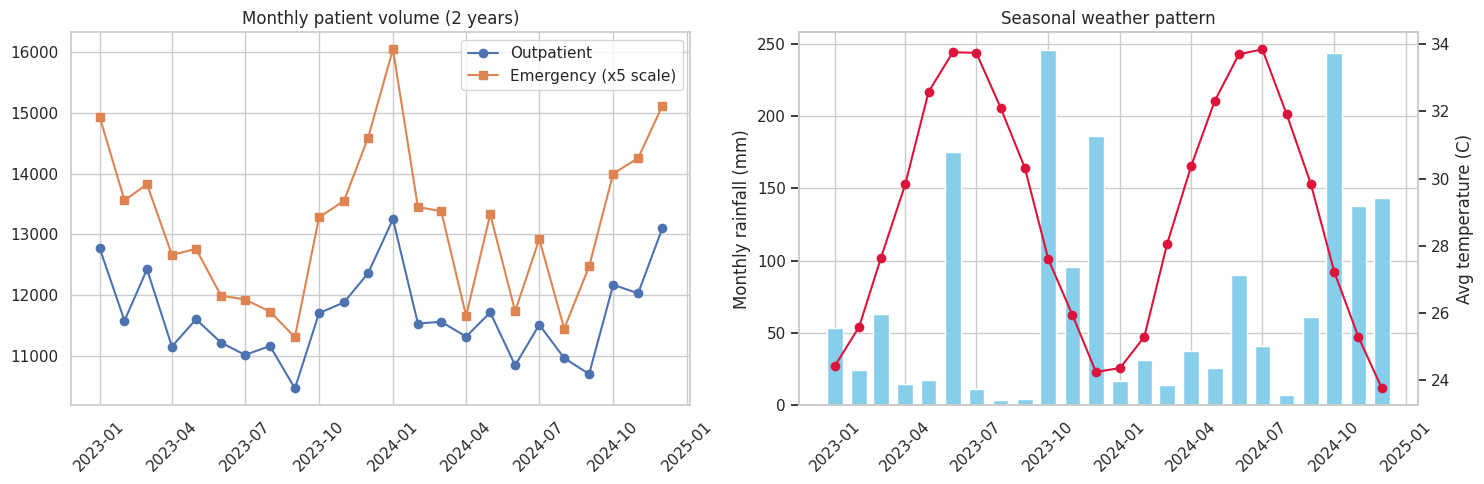

In [6]:
daily = df.groupby("Date").agg(Outpatient=("Outpatient_Count","sum"), Emergency=("Emergency_Count","sum"),
                              Temperature=("Temperature","first"), Rainfall=("Rainfall","first")).reset_index()
monthly = daily.set_index("Date").resample("MS").agg({"Outpatient":"sum","Emergency":"sum","Temperature":"mean","Rainfall":"sum"})

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(monthly.index, monthly["Outpatient"], marker="o", label="Outpatient")
ax[0].plot(monthly.index, monthly["Emergency"]*5, marker="s", label="Emergency (x5 scale)")
ax[0].set_title("Monthly patient volume (2 years)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=45)

ax2 = ax[1]; ax2.bar(monthly.index, monthly["Rainfall"], width=20, color="skyblue", label="Rainfall (mm)")
ax2.set_ylabel("Monthly rainfall (mm)"); ax2.tick_params(axis="x", rotation=45)
ax3 = ax2.twinx(); ax3.plot(monthly.index, monthly["Temperature"], color="crimson", marker="o", label="Avg temp (C)")
ax3.set_ylabel("Avg temperature (C)"); ax3.grid(False)
ax2.set_title("Seasonal weather pattern")
plt.tight_layout(); plt.show()

### Viz 2 — Patient volume under different weather conditions

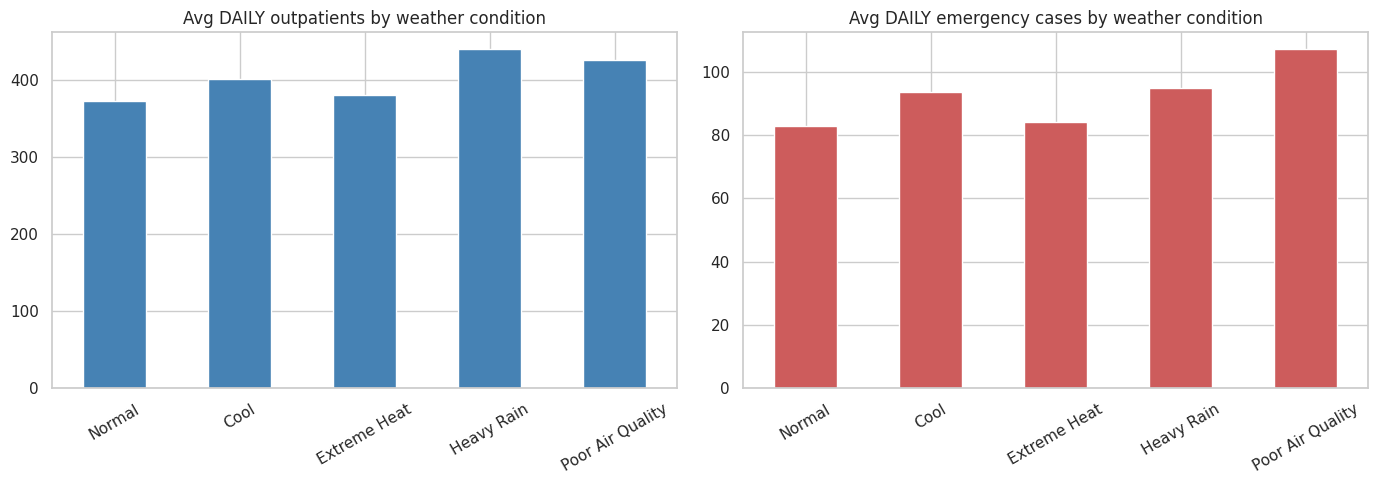

,Outpatient_Count (% vs Normal),Emergency_Count (% vs Normal)
Weather_Condition,,
Normal,0.0,0.0
Cool,7.5,13.1
Extreme Heat,1.9,1.6
Heavy Rain,17.9,14.7
Poor Air Quality,14.3,29.4


In [7]:
order = ["Normal","Cool","Extreme Heat","Heavy Rain","Poor Air Quality"]
avg = df.groupby(["Date","Weather_Condition"])[["Outpatient_Count","Emergency_Count"]].sum().reset_index()
avg = avg.groupby("Weather_Condition")[["Outpatient_Count","Emergency_Count"]].mean().reindex(order)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
avg["Outpatient_Count"].plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Avg DAILY outpatients by weather condition")
avg["Emergency_Count"].plot.bar(ax=ax[1], color="indianred");  ax[1].set_title("Avg DAILY emergency cases by weather condition")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
display((avg / avg.loc["Normal"] - 1).mul(100).round(1).rename(columns=lambda c: c+" (% vs Normal)"))

### Viz 3 — Correlation heatmap (weather vs patient counts)

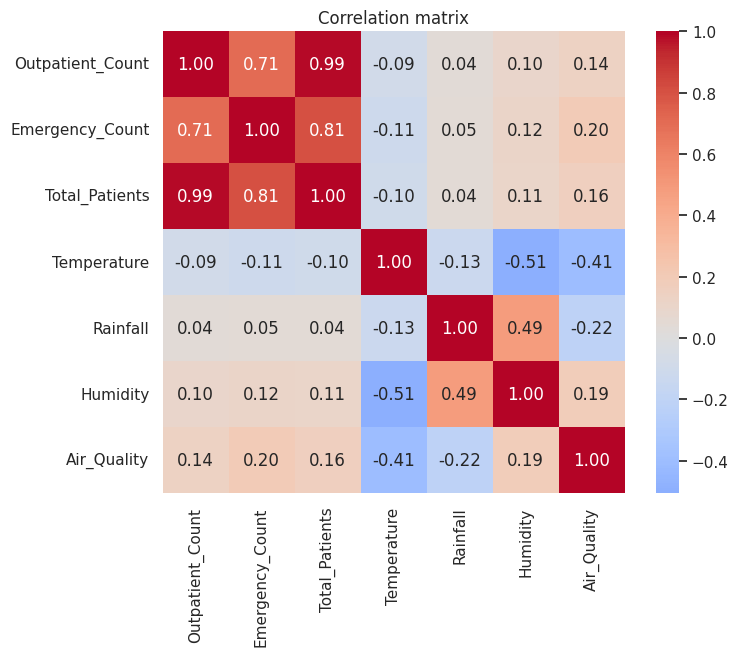

In [8]:
cols = ["Outpatient_Count","Emergency_Count","Total_Patients","Temperature","Rainfall","Humidity","Air_Quality"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix"); plt.show()

### Viz 4 — Which departments are most affected by weather?

/tmp/ipykernel_3386/3699723835.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sens = pd.DataFrame({v: df.groupby("Department").apply(lambda g: g["Total_Patients"].corr(g[v])) for v in weather_vars})
/tmp/ipykernel_3386/3699723835.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sens = pd.DataFrame({v: df.groupby("Department").apply(lambda g: g["Total_Patients"].corr(g[v])) for v in weather_vars})
/t

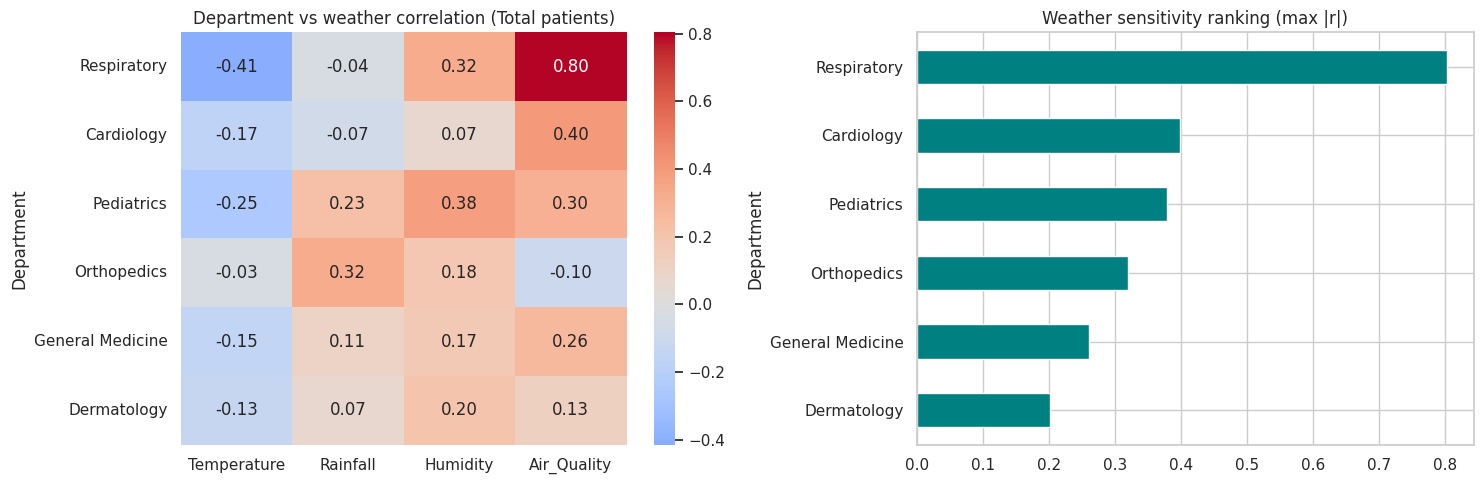

,Temperature,Rainfall,Humidity,Air_Quality,Max_Abs_Correlation
Department,,,,,
Respiratory,-0.414,-0.037,0.323,0.804,0.804
Cardiology,-0.166,-0.073,0.071,0.398,0.398
Pediatrics,-0.251,0.228,0.379,0.302,0.379
Orthopedics,-0.029,0.321,0.183,-0.103,0.321
General Medicine,-0.147,0.108,0.175,0.261,0.261
Dermatology,-0.128,0.066,0.201,0.127,0.201


In [9]:
weather_vars = ["Temperature","Rainfall","Humidity","Air_Quality"]
sens = pd.DataFrame({v: df.groupby("Department").apply(lambda g: g["Total_Patients"].corr(g[v])) for v in weather_vars})
sens["Max_Abs_Correlation"] = sens.abs().max(axis=1)
sens = sens.sort_values("Max_Abs_Correlation", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(sens[weather_vars], annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title("Department vs weather correlation (Total patients)")
sens["Max_Abs_Correlation"].sort_values().plot.barh(ax=ax[1], color="teal")
ax[1].set_title("Weather sensitivity ranking (max |r|)")
plt.tight_layout(); plt.show()
display(sens.round(3))

## 6. Is the relationship statistically meaningful?

In [10]:
daily_tot = df.groupby("Date").agg(Total=("Total_Patients","sum"), Emergency=("Emergency_Count","sum"),
        Temperature=("Temperature","first"), Rainfall=("Rainfall","first"),
        Humidity=("Humidity","first"), Air_Quality=("Air_Quality","first"),
        Weather_Condition=("Weather_Condition","first")).reset_index()

res = []
for v in weather_vars:
    r, p = stats.pearsonr(daily_tot[v], daily_tot["Total"])
    rho, p_s = stats.spearmanr(daily_tot[v], daily_tot["Total"])
    res.append([v, r, p, rho, p_s])
corr_tbl = pd.DataFrame(res, columns=["Weather_Var","Pearson_r","Pearson_p","Spearman_rho","Spearman_p"]).round(4)
display(corr_tbl)

# One-way ANOVA: do daily totals differ across weather conditions?
groups = [g["Total"].values for _, g in daily_tot.groupby("Weather_Condition")]
f, p = stats.f_oneway(*groups)
print(f"ANOVA (Total patients across weather conditions): F={f:.2f}, p={p:.4g}")

# Extreme weather vs normal days (Welch t-test)
normal = daily_tot.loc[daily_tot.Weather_Condition=="Normal","Total"]
extreme = daily_tot.loc[daily_tot.Weather_Condition!="Normal","Total"]
t, p = stats.ttest_ind(extreme, normal, equal_var=False)
print(f"Extreme vs Normal days: mean {extreme.mean():.0f} vs {normal.mean():.0f}, t={t:.2f}, p={p:.4g}")
print("\nInterpretation: p < 0.05 => evidence AGAINST 'weather has no effect'.")

,Weather_Var,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Temperature,-0.2598,0.0000,-0.2821,0.0000
1,Rainfall,0.1154,0.0018,0.1028,0.0054
2,Humidity,0.2866,0.0000,0.3025,0.0000
3,Air_Quality,0.4317,0.0000,0.4607,0.0000


ANOVA (Total patients across weather conditions): F=19.47, p=3.103e-15
Extreme vs Normal days: mean 501 vs 456, t=6.39, p=5.031e-10

Interpretation: p < 0.05 => evidence AGAINST 'weather has no effect'.


## 7. Linear Regression model
**Target:** `Total_Patients` (Outpatient + Emergency) per department per day.
**Features:** Temperature, Rainfall, Humidity, Air_Quality, weekday, month, department (one-hot).
**Split:** time-based (first ~80% of dates train, last ~20% test) — realistic for forecasting and avoids leakage.

In [11]:
features_num = ["Temperature","Rainfall","Humidity","Air_Quality","DayOfWeek","Month"]
X = pd.get_dummies(df[features_num + ["Department"]], columns=["Department"], drop_first=True).astype(float)
y = df["Total_Patients"]

cutoff = df["Date"].quantile(0.8)
train, test = df["Date"] <= cutoff, df["Date"] > cutoff
X_train, X_test, y_train, y_test = X[train], X[test], y[train], y[test]

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2   = r2_score(y_test, pred)
baseline = np.full_like(y_test, y_train.mean(), dtype=float)
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"MAE  = {mae:.2f} patients | RMSE = {rmse:.2f} | R2 = {r2:.3f}")
print(f"Baseline (predict mean) MAE = {mean_absolute_error(y_test, baseline):.2f}")

coef = pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("\nCoefficients (patients per 1-unit change):"); display(coef.round(3))

Train rows: 3510 | Test rows: 876
MAE  = 10.64 patients | RMSE = 13.82 | R2 = 0.870
Baseline (predict mean) MAE = 29.02

Coefficients (patients per 1-unit change):


,0
Department_General Medicine,81.089
Department_Dermatology,-20.356
Department_Pediatrics,19.243
Department_Orthopedics,-5.658
DayOfWeek,-5.180
Department_Respiratory,-1.039
Rainfall,0.334
Air_Quality,0.285
Month,-0.143
Humidity,0.133


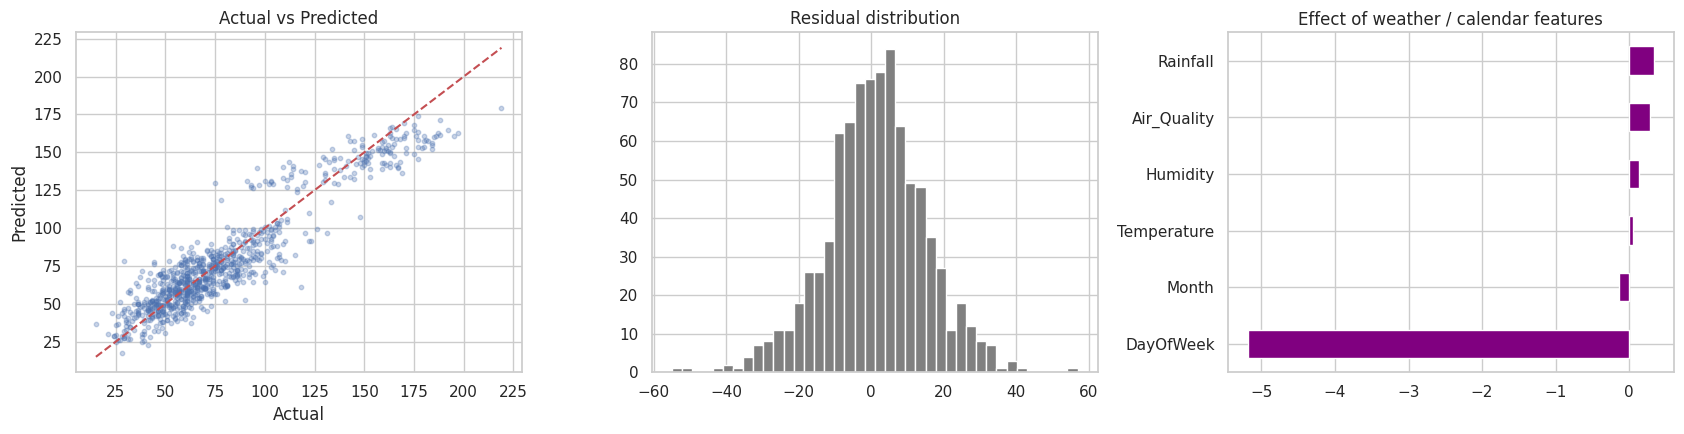

R2 without weather: 0.815  |  with weather: 0.870


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test, pred, alpha=.3, s=10); lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs Predicted")
ax[1].hist(y_test - pred, bins=40, color="gray"); ax[1].set_title("Residual distribution")
coef.drop([c for c in coef.index if c.startswith("Department_")]).sort_values().plot.barh(ax=ax[2], color="purple")
ax[2].set_title("Effect of weather / calendar features")
plt.tight_layout(); plt.show()

# Does weather add predictive value? Compare against calendar+department only
base_cols = [c for c in X.columns if c not in ["Temperature","Rainfall","Humidity","Air_Quality"]]
m0 = LinearRegression().fit(X_train[base_cols], y_train)
print(f"R2 without weather: {r2_score(y_test, m0.predict(X_test[base_cols])):.3f}  |  with weather: {r2:.3f}")


## 8. Practical action plan
| Trigger | Action | Owner | Lead time |
|---|---|---|---|
| Heat / AQI forecast above threshold | Add staff in the most-affected departments; stock relevant supplies | Dept heads | 24–48 h |
| Heavy rain forecast | Prepare emergency/orthopaedic capacity; alert ambulance services | ER manager | 24 h |
| Monsoon/summer season starts | Adjust seasonal rosters and inventory | HR / Pharmacy | 2–4 weeks |
| Ongoing | Feed weather forecasts into this model for daily arrival forecasts; retrain quarterly | Analytics | Monthly |

**Limitations:** correlation ≠ causation; linear model can't capture non-linear/heat-threshold effects (next step: add interaction terms, lagged weather, or try tree-based models).